# CIFAR-10 with 500 images: learning under distribution shift

**Goal:** train a small Inception-style CNN (332,714 parameters, from scratch) on 400 clean CIFAR-10 images and make it work on a shifted test set (rotation, brightness/contrast, blur/noise, 25% occlusion, one hidden corruption).

**Key results (mean ± std over 3 seeds)**

| | Clean test | Shifted test |
|---|---|---|
| No augmentation | 45.41 ± 0.07 | 16.28 ± 0.90 |
| Final model | 41.26 ± 1.93 | 23.03 ± 0.52 |

Augmentation raised shifted accuracy by about **6.7 points**, but accuracy is still low (chance = 10%). It also cost about 4 points on clean images. With only 400 training images, this is the honest outcome.

**Setup notes**
- All seeds are fixed and printed in the setup cells. Settings were chosen on the validation split only. Test sets are used only for reporting.
- The exact hidden corruption was not provided, so `hidden_corruption()` implements it as **random grayscale or random channel swap** (each on about 25% of images, the rest untouched). This is our own implementation of the unlisted corruption.

## 0. Setup

In [1]:
import os, time, math, random, json, hashlib, textwrap
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.metrics import confusion_matrix

SMOKE = False            # True = tiny pipeline check only (never use for reported numbers)

# ---- all seeds in one place -------------------------------------------------
DATA_SEED       = 0                  # train_small selection + 400/100 split
EVAL_SEEDS      = [0, 1, 2]          # the 3 reported training seeds
SEARCH_SEED     = 100                # hyper-parameter search (validation only)
SHIFT_TEST_SEED = 2024               # fixed corruption pipeline for shifted_test
SHIFT_VAL_SEED  = 777                # corrupted copy of the 100 validation images
EPOCHS          = 60 if not SMOKE else 2
BATCH           = 64

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print("device:", device, "| torch", torch.__version__, "| torchvision", torchvision.__version__)
print(dict(DATA_SEED=DATA_SEED, EVAL_SEEDS=EVAL_SEEDS, SEARCH_SEED=SEARCH_SEED,
           SHIFT_TEST_SEED=SHIFT_TEST_SEED, SHIFT_VAL_SEED=SHIFT_VAL_SEED, EPOCHS=EPOCHS, BATCH=BATCH))

device: cuda | torch 2.11.0+cu130 | torchvision 0.26.0+cu130
{'DATA_SEED': 0, 'EVAL_SEEDS': [0, 1, 2], 'SEARCH_SEED': 100, 'SHIFT_TEST_SEED': 2024, 'SHIFT_VAL_SEED': 777, 'EPOCHS': 60, 'BATCH': 64}


### 0.1 Data: `train_small` (500) → 400 train / 100 validation, `clean_test` (10 000)
50 images per class are drawn with `RandomState(DATA_SEED)`; for each class 40 go to train and 10 to validation (stratified).

In [2]:
CLASSES = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']

if SMOKE:   # synthetic stand-in, only to test the code path
    rs = np.random.RandomState(0)
    class _D:  pass
    tr, te = _D(), _D()
    tr.data = rs.randint(0,255,(5000,32,32,3),dtype=np.uint8); tr.targets = list(np.arange(5000)%10)
    te.data = rs.randint(0,255,(1000,32,32,3),dtype=np.uint8); te.targets = list(np.arange(1000)%10)
else:
    tr = torchvision.datasets.CIFAR10('./data', train=True,  download=True)
    te = torchvision.datasets.CIFAR10('./data', train=False, download=True)

to_t = lambda a: torch.from_numpy(a).permute(0,3,1,2).float().div(255.)
ytr_all, yte = np.array(tr.targets), torch.tensor(te.targets)

rng = np.random.RandomState(DATA_SEED)
tr_idx, va_idx = [], []
for c in range(10):
    idx = rng.choice(np.where(ytr_all == c)[0], 50, replace=False)   # train_small: 50 / class
    tr_idx += list(idx[:40]); va_idx += list(idx[40:])               # 40 train / 10 val per class
tr_idx, va_idx = np.array(tr_idx), np.array(va_idx)
assert len(set(tr_idx) & set(va_idx)) == 0

Xtr, Ytr = to_t(tr.data[tr_idx]), torch.tensor(ytr_all[tr_idx])
Xva, Yva = to_t(tr.data[va_idx]), torch.tensor(ytr_all[va_idx])
Xte_clean = to_t(te.data)

print("train:", tuple(Xtr.shape), "val:", tuple(Xva.shape), "clean_test:", tuple(Xte_clean.shape))
print("train per class:", np.bincount(Ytr.numpy()), "| val per class:", np.bincount(Yva.numpy()))
print("split fingerprint (md5 of indices):", hashlib.md5(np.concatenate([tr_idx, va_idx]).tobytes()).hexdigest()[:12])

100%|██████████| 170M/170M [33:28<00:00, 84.9kB/s]


train: (400, 3, 32, 32) val: (100, 3, 32, 32) clean_test: (10000, 3, 32, 32)
train per class: [40 40 40 40 40 40 40 40 40 40] | val per class: [10 10 10 10 10 10 10 10 10 10]
split fingerprint (md5 of indices): ff2aa4f680a8


### 0.2 Shifted test set (fixed, seeded corruption pipeline)
Order of operations per image: **rotation (±25°) → contrast & brightness → blur (p=0.5) + Gaussian noise → hidden corruption → 16×16 black occlusion (= 25 % of the image)**.
The same pipeline (but **without** the hidden corruption) is applied once, with another seed, to the 100 validation images, giving a *shifted validation* set that is legitimate for model selection.

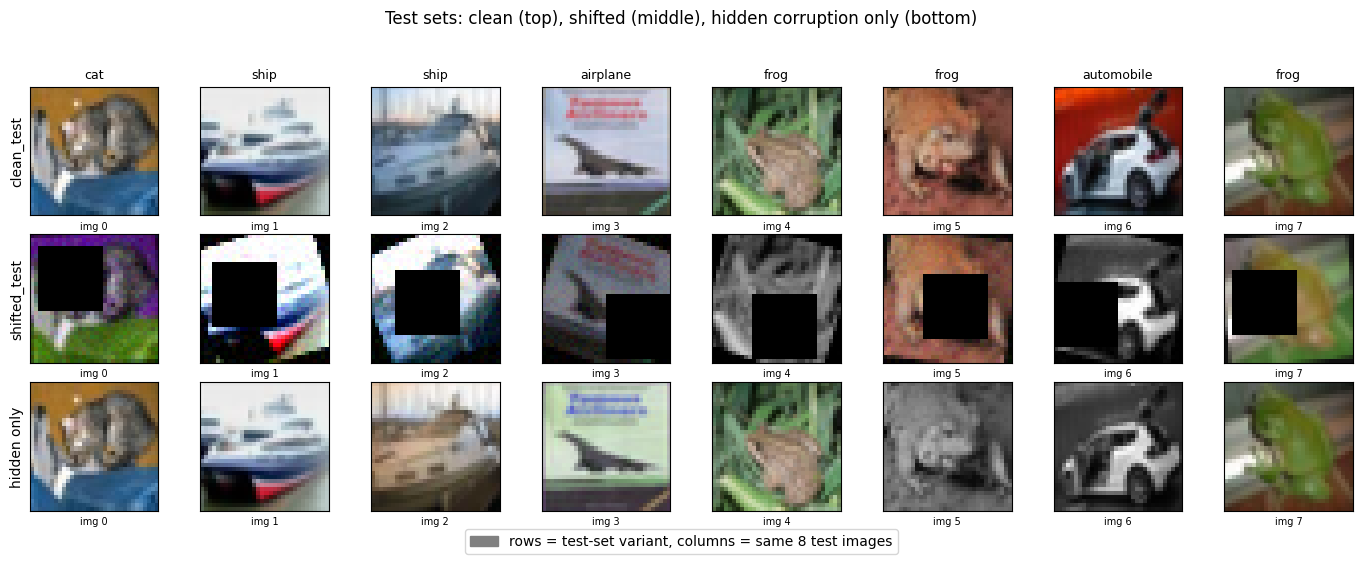

In [3]:
def gaussian_blur_batch(x, sigma, k=5):
    """Per-image Gaussian blur. x: (N,C,H,W), sigma: (N,)"""
    N, C, H, W = x.shape
    ax = torch.arange(k, device=x.device).float() - k // 2
    ker = torch.exp(-ax[None, :] ** 2 / (2 * sigma[:, None].clamp(min=1e-3) ** 2))
    ker = (ker / ker.sum(1, keepdim=True)).repeat_interleave(C, 0)           # (N*C, k)
    y = x.reshape(1, N * C, H, W)
    y = F.conv2d(F.pad(y, (k//2, k//2, 0, 0), mode='reflect'), ker.view(N*C, 1, 1, k), groups=N*C)
    y = F.conv2d(F.pad(y, (0, 0, k//2, k//2), mode='reflect'), ker.view(N*C, 1, k, 1), groups=N*C)
    return y.reshape(N, C, H, W)

def rotate_batch(x, angles_deg):
    a = angles_deg * math.pi / 180
    z = torch.zeros_like(a)
    theta = torch.stack([torch.stack([a.cos(), -a.sin(), z], 1),
                         torch.stack([a.sin(),  a.cos(), z], 1)], 1)         # (N,2,3)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, padding_mode='zeros', align_corners=False)

PERMS = torch.tensor([[1,0,2],[2,1,0],[0,2,1],[1,2,0],[2,0,1]])

def hidden_corruption(x, g, p=0.5):
    """Hidden corruption (exact details were not provided, so this is our own implementation).
    With prob p/2 -> grayscale, with prob p/2 -> random channel permutation, else untouched.
    Returns (corrupted images, kind) with kind 0 = none, 1 = grayscale, 2 = channel swap."""
    N = x.shape[0]
    r = torch.rand(N, generator=g)
    kind = torch.zeros(N, dtype=torch.long); kind[r < p/2] = 1; kind[(r >= p/2) & (r < p)] = 2
    out = x.clone()
    gray = (0.299*x[:,0] + 0.587*x[:,1] + 0.114*x[:,2]).unsqueeze(1).expand(-1, 3, -1, -1)
    out[kind == 1] = gray[kind == 1]
    pick = PERMS[torch.randint(0, 5, (N,), generator=g)]                      # (N,3)
    swapped = torch.gather(x, 1, pick[:, :, None, None].expand(-1, -1, x.shape[2], x.shape[3]))
    out[kind == 2] = swapped[kind == 2]
    return out, kind

def make_shifted(x, seed, hidden=True):
    g = torch.Generator().manual_seed(seed); N = x.shape[0]
    ang = (torch.rand(N, generator=g) * 2 - 1) * 25.0
    x = rotate_batch(x, ang)
    bri = 0.5 + torch.rand(N, generator=g)                  # 0.5 (dark) .. 1.5 (bright)
    con = 0.6 + 0.8 * torch.rand(N, generator=g)            # 0.6 .. 1.4
    m = x.mean((1, 2, 3), keepdim=True)
    x = (((x - m) * con.view(-1,1,1,1) + m) * bri.view(-1,1,1,1)).clamp(0, 1)
    sig = torch.where(torch.rand(N, generator=g) < 0.5, 0.5 + 0.7 * torch.rand(N, generator=g), torch.full((N,), 0.05))
    x = gaussian_blur_batch(x, sig)
    nstd = 0.06 * torch.rand(N, generator=g)
    x = (x + torch.randn(x.shape, generator=g) * nstd.view(-1,1,1,1)).clamp(0, 1)
    kind = torch.zeros(N, dtype=torch.long)
    if hidden: x, kind = hidden_corruption(x, g)
    top, left = torch.randint(0, 17, (N,), generator=g), torch.randint(0, 17, (N,), generator=g)
    ar = torch.arange(32)
    rm = (ar[None] >= top[:, None]) & (ar[None] < top[:, None] + 16)
    cm = (ar[None] >= left[:, None]) & (ar[None] < left[:, None] + 16)
    x = x.masked_fill((rm[:, :, None] & cm[:, None, :]).unsqueeze(1), 0.0)    # 16x16 / 32x32 = 25 %
    meta = dict(angle=ang, bright=bri, contrast=con, sigma=sig, noise=nstd, top=top, left=left, hidden=kind)
    return x, meta

Xte_shift, META_SH = make_shifted(Xte_clean, SHIFT_TEST_SEED, hidden=True)          # shifted_test
Xva_shift, _       = make_shifted(Xva,       SHIFT_VAL_SEED,  hidden=False)         # shifted validation (no hidden op)
g_h = torch.Generator().manual_seed(SHIFT_TEST_SEED + 1)
Xte_hidden, KIND_HID = hidden_corruption(Xte_clean, g_h)                            # hidden corruption ONLY (Part E4)

fig, axs = plt.subplots(3, 8, figsize=(14, 5.6))
for j in range(8):
    for i, (X, nm) in enumerate([(Xte_clean, 'clean_test'), (Xte_shift, 'shifted_test'), (Xte_hidden, 'hidden only')]):
        axs[i, j].imshow(X[j].permute(1, 2, 0).clamp(0, 1).numpy()); axs[i, j].set_xticks([]); axs[i, j].set_yticks([])
        if j == 0: axs[i, j].set_ylabel(nm)
        if i == 0: axs[i, j].set_title(CLASSES[int(yte[j])], fontsize=9)
        axs[i, j].set_xlabel(f"img {j}", fontsize=7)
fig.suptitle("Test sets: clean (top), shifted (middle), hidden corruption only (bottom)")
fig.legend(handles=[Patch(color='gray', label='rows = test-set variant, columns = same 8 test images')], loc='lower center')
plt.tight_layout(rect=(0, 0.04, 1, 0.95)); plt.show()

### 0.3 Training-time augmentation library (on the fly, GPU, training batches only)

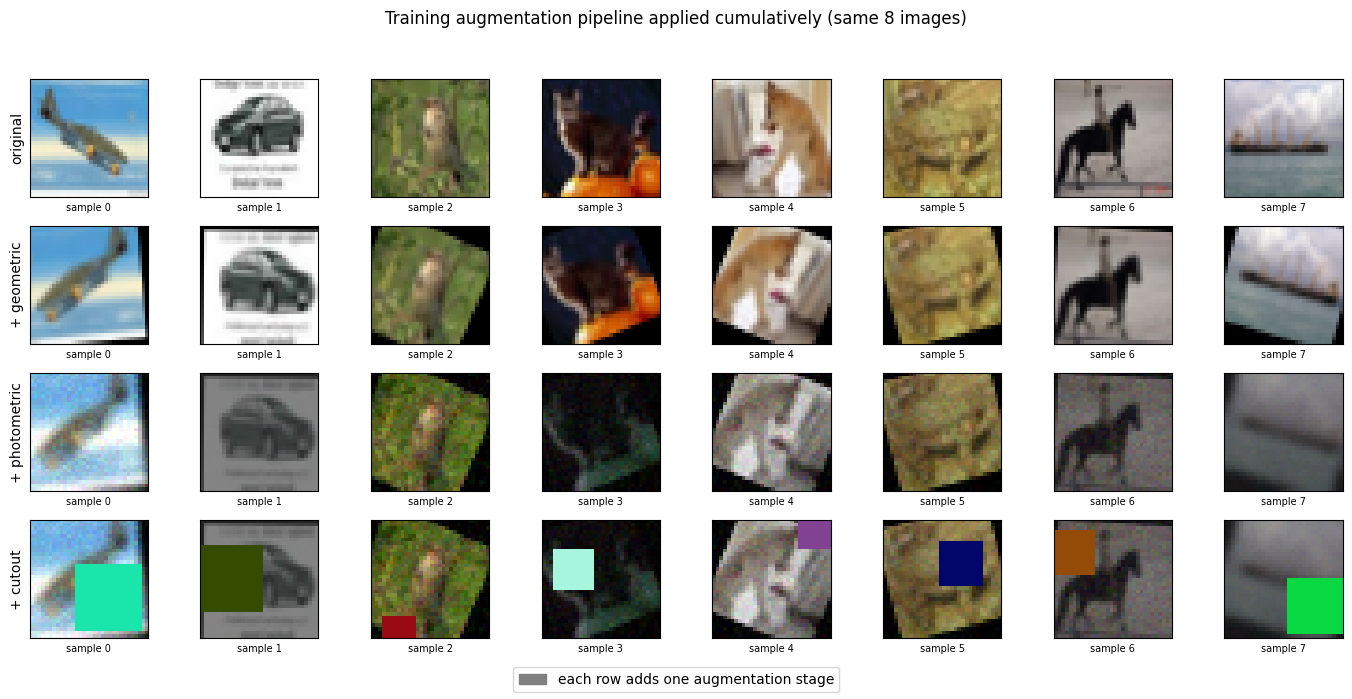

In [4]:
def aug_geometric(x, rot=25., trans=0.1, scale=(0.9, 1.1), hflip=True, vflip=False):
    """random rotation + translation (= random crop with zero padding) + scale + flips, one affine warp."""
    N, d = x.shape[0], x.device
    a = (torch.rand(N, device=d) * 2 - 1) * rot * math.pi / 180
    s = scale[0] + (scale[1] - scale[0]) * torch.rand(N, device=d)
    tx, ty = [(torch.rand(N, device=d) * 2 - 1) * trans * 2 for _ in range(2)]      # normalised coords: 2 = full width
    fx = (torch.rand(N, device=d) < 0.5).float() * 2 - 1 if hflip else torch.ones(N, device=d)
    fy = (torch.rand(N, device=d) < 0.5).float() * 2 - 1 if vflip else torch.ones(N, device=d)
    c, sn = a.cos() / s, a.sin() / s
    theta = torch.stack([torch.stack([c * fx, -sn * fy, tx], 1), torch.stack([sn * fx, c * fy, ty], 1)], 1)   # R @ diag(fx, fy)
    return F.grid_sample(x, F.affine_grid(theta, list(x.shape), align_corners=False), padding_mode='zeros', align_corners=False)

def aug_photometric(x, bri=(0.5, 1.5), con=(0.6, 1.4), sat=(0.0, 1.5), perm_p=0.1, blur_p=0.3, noise=0.06):
    """colour jitter (brightness / contrast / saturation incl. full desaturation) + blur + noise + rare channel shuffle"""
    N, d = x.shape[0], x.device
    U = lambda lo, hi: (lo + (hi - lo) * torch.rand(N, device=d)).view(-1, 1, 1, 1)
    gray = (0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3])
    x = gray + (x - gray) * U(*sat)
    m = x.mean((1, 2, 3), keepdim=True)
    x = ((x - m) * U(*con) + m) * U(*bri)
    sig = torch.where(torch.rand(N, device=d) < blur_p, 0.4 + 0.9 * torch.rand(N, device=d), torch.full((N,), 0.05, device=d))
    x = gaussian_blur_batch(x.clamp(0, 1), sig)
    x = x + torch.randn_like(x) * U(0, noise)
    pick = PERMS.to(d)[torch.randint(0, 5, (N,), device=d)]
    swapped = torch.gather(x, 1, pick[:, :, None, None].expand(-1, -1, x.shape[2], x.shape[3]))
    x = torch.where((torch.rand(N, device=d) < perm_p).view(-1, 1, 1, 1), swapped, x)
    return x.clamp(0, 1)

def aug_cutout(x, p=0.8, smin=8, smax=18):
    """Random Erasing / Cutout: one box of random size & position (may be clipped), random constant colour."""
    N, d = x.shape[0], x.device
    size = torch.randint(smin, smax + 1, (N,), device=d)
    cy, cx = torch.randint(0, 32, (N,), device=d), torch.randint(0, 32, (N,), device=d)
    ar = torch.arange(32, device=d)
    rm = (ar[None] >= (cy - size // 2)[:, None]) & (ar[None] < (cy - size // 2 + size)[:, None])
    cm = (ar[None] >= (cx - size // 2)[:, None]) & (ar[None] < (cx - size // 2 + size)[:, None])
    box = (rm[:, :, None] & cm[:, None, :]).unsqueeze(1) & (torch.rand(N, device=d) < p).view(-1, 1, 1, 1)
    return torch.where(box, torch.rand(N, 3, 1, 1, device=d).expand_as(x), x)

def mix_batch(x, y, mix_p=0.5, mixup_alpha=0.4, cutmix_alpha=1.0):
    """with prob mix_p: half the time Mixup, half the time CutMix. y are soft labels."""
    if random.random() > mix_p: return x, y
    perm = torch.randperm(x.shape[0], device=x.device)
    if random.random() < 0.5:
        lam = float(np.random.beta(mixup_alpha, mixup_alpha)); x = lam * x + (1 - lam) * x[perm]
    else:
        lam = float(np.random.beta(cutmix_alpha, cutmix_alpha)); r = math.sqrt(1 - lam)
        h = w = int(32 * r); cy, cx = np.random.randint(32), np.random.randint(32)
        t, b, l, rr = max(cy - h // 2, 0), min(cy + h // 2, 32), max(cx - w // 2, 0), min(cx + w // 2, 32)
        x = x.clone(); x[:, :, t:b, l:rr] = x[perm][:, :, t:b, l:rr]
        lam = 1 - (b - t) * (rr - l) / 1024.
    return x, lam * y + (1 - lam) * y[perm]

# ---- visual check of the training pipeline ---------------------------------
set_seed(0)
xs = Xtr[::50][:8].to(device)
stages = [('original', xs), ('+ geometric', aug_geometric(xs))]
stages.append(('+ photometric', aug_photometric(stages[-1][1])))
stages.append(('+ cutout', aug_cutout(stages[-1][1], p=1.0)))
fig, axs = plt.subplots(len(stages), 8, figsize=(14, 7))
for i, (nm, X) in enumerate(stages):
    for j in range(8):
        axs[i, j].imshow(X[j].permute(1, 2, 0).clamp(0, 1).cpu().numpy()); axs[i, j].set_xticks([]); axs[i, j].set_yticks([])
        if j == 0: axs[i, j].set_ylabel(nm)
        axs[i, j].set_xlabel(f"sample {j}", fontsize=7)
fig.suptitle("Training augmentation pipeline applied cumulatively (same 8 images)")
fig.legend(handles=[Patch(color='gray', label='each row adds one augmentation stage')], loc='lower center')
plt.tight_layout(rect=(0, 0.04, 1, 0.95)); plt.show()

### 0.4 Model: AlexNet/LeNet-style stem + two Inception modules + conv head
`Inception` = parallel **1×1**, **1×1→3×3**, **1×1→5×5** and **maxpool→1×1** branches (the 1×1 reductions keep the 3×3 / 5×5 branches cheap), concatenated on the channel axis. Input normalisation lives inside the model so every augmentation works on `[0,1]` images.

In [5]:
class ConvBNReLU(nn.Sequential):
    def __init__(self, i, o, k, p=0):
        super().__init__(nn.Conv2d(i, o, k, padding=p, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class Inception(nn.Module):
    def __init__(self, i, c1, c3r, c3, c5r, c5, cp):
        super().__init__()
        self.b1 = ConvBNReLU(i, c1, 1)
        self.b2 = nn.Sequential(ConvBNReLU(i, c3r, 1), ConvBNReLU(c3r, c3, 3, 1))
        self.b3 = nn.Sequential(ConvBNReLU(i, c5r, 1), ConvBNReLU(c5r, c5, 5, 2))
        self.b4 = nn.Sequential(nn.MaxPool2d(3, 1, 1), ConvBNReLU(i, cp, 1))
        self.out_ch = c1 + c3 + c5 + cp
    def forward(self, x): return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], 1)

class Net(nn.Module):
    def __init__(self, drop=0.3, n_cls=10):
        super().__init__()
        self.register_buffer('mean', torch.tensor([0.4914, 0.4822, 0.4465]).view(1, 3, 1, 1))
        self.register_buffer('std',  torch.tensor([0.2470, 0.2435, 0.2616]).view(1, 3, 1, 1))
        self.stem = nn.Sequential(ConvBNReLU(3, 32, 3, 1), nn.MaxPool2d(2))            # 32 -> 16
        self.inc1 = Inception(32, 16, 24, 32, 8, 16, 16)                               # -> 80 ch
        self.pool1 = nn.MaxPool2d(2)                                                   # 16 -> 8
        self.inc2 = Inception(80, 32, 32, 64, 16, 32, 32)                              # -> 160 ch
        self.pool2 = nn.MaxPool2d(2)                                                   # 8 -> 4
        self.head = ConvBNReLU(160, 192, 3, 1)
        self.gap, self.drop, self.fc = nn.AdaptiveAvgPool2d(1), nn.Dropout(drop), nn.Linear(192, n_cls)
    def forward(self, x):
        x = (x - self.mean) / self.std
        x = self.pool1(self.inc1(self.stem(x))); x = self.pool2(self.inc2(x))
        return self.fc(self.drop(self.gap(self.head(x)).flatten(1)))

n_params = sum(p.numel() for p in Net().parameters() if p.requires_grad)
print(f"trainable parameters: {n_params:,}")
assert n_params <= 1_000_000, "violates the 1M parameter limit"

trainable parameters: 332,714


### 0.5 Training / evaluation loop
* optimiser: SGD + Nesterov momentum, **OneCycle** LR schedule, weight decay; 60 epochs; batch 64 (`drop_last`), fixed seed per run.
* loss: cross-entropy on (possibly mixed, possibly smoothed) **soft** labels.
* **Early stopping = best-checkpoint selection**: after every epoch the model is scored on validation only, `val_sel = ½·(clean-val acc + shifted-val acc)`; the best epoch's weights are restored before any test evaluation.
* the test sets are touched exactly once per run, after the checkpoint is fixed.

In [6]:
DEFAULTS = dict(geo=False, photo=False, cutout=False, mix=False, ls=0.0,
                lr=0.05, wd=5e-4, drop=0.3, rot=25., trans=0.1, vflip=False, mix_p=0.5)

Xtr_d, Ytr_d = Xtr.to(device), Ytr.to(device)
Xva_d, Yva_d, Xvs_d = Xva.to(device), Yva.to(device), Xva_shift.to(device)

@torch.no_grad()
def predict(model, X, bs=1000):
    model.eval()
    return torch.cat([model(X[i:i+bs].to(device)) for i in range(0, len(X), bs)])

def acc_of(logits, Y): return (logits.argmax(1).cpu() == Y.cpu()).float().mean().item()

def apply_aug(x, c):
    if c['geo']:    x = aug_geometric(x, rot=c['rot'], trans=c['trans'], vflip=c['vflip'])
    if c['photo']:  x = aug_photometric(x)
    if c['cutout']: x = aug_cutout(x)
    return x

def train_eval(cfg, seed, keep_model=False, test=True):
    c = {**DEFAULTS, **cfg}; set_seed(seed)
    model = Net(c['drop']).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=c['lr'], momentum=0.9, nesterov=True, weight_decay=c['wd'])
    spe = len(Xtr_d) // BATCH
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=c['lr'], total_steps=EPOCHS * spe, pct_start=0.15)
    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'val_shift_acc']}
    best, best_state, best_ep = -1, None, 0
    for ep in range(EPOCHS):
        model.train(); perm = torch.randperm(len(Xtr_d), device=device); tl = 0.
        for b in range(spe):
            i = perm[b * BATCH:(b + 1) * BATCH]
            x = apply_aug(Xtr_d[i], c)
            y = F.one_hot(Ytr_d[i], 10).float() * (1 - c['ls']) + c['ls'] / 10
            if c['mix']: x, y = mix_batch(x, y, c['mix_p'])
            loss = -(y * F.log_softmax(model(x), 1)).sum(1).mean()
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step(); tl += loss.item()
        lt, lv, ls_ = predict(model, Xtr_d), predict(model, Xva_d), predict(model, Xvs_d)
        hist['train_loss'].append(tl / spe); hist['train_acc'].append(acc_of(lt, Ytr))
        hist['val_loss'].append(F.cross_entropy(lv, Yva_d).item())
        hist['val_acc'].append(acc_of(lv, Yva)); hist['val_shift_acc'].append(acc_of(ls_, Yva))
        sel = 0.5 * (hist['val_acc'][-1] + hist['val_shift_acc'][-1])
        if sel > best:
            best, best_ep = sel, ep; best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    res = dict(cfg=c, seed=seed, best_epoch=best_ep, hist=hist, val_sel=best,
               train_acc=acc_of(predict(model, Xtr_d), Ytr),
               val_acc=hist['val_acc'][best_ep], val_shift_acc=hist['val_shift_acc'][best_ep])
    if test:   # reporting only; the checkpoint is already fixed
        pc, ps, ph = predict(model, Xte_clean), predict(model, Xte_shift), predict(model, Xte_hidden)
        res.update(clean_acc=acc_of(pc, yte), shift_acc=acc_of(ps, yte), hidden_acc=acc_of(ph, yte),
                   pred_clean=pc.argmax(1).cpu(), pred_shift=ps.argmax(1).cpu(), pred_hidden=ph.argmax(1).cpu())
    if keep_model: res['state'] = {k: v.cpu() for k, v in model.state_dict().items()}
    return res

def run_seeds(name, cfg, seeds=EVAL_SEEDS, keep_model=False):
    t0 = time.time(); out = [train_eval(cfg, s, keep_model) for s in seeds]
    print(f"{name:<42s} val {np.mean([r['val_acc'] for r in out]):.3f} | clean {np.mean([r['clean_acc'] for r in out]):.3f} "
          f"| shifted {np.mean([r['shift_acc'] for r in out]):.3f}  ({time.time()-t0:.0f}s)")
    return out

ms = lambda v: f"{100*np.mean(v):.2f} ± {100*np.std(v):.2f}"

## Part A: Baseline (no augmentation)

No augmentation                            val 0.447 | clean 0.454 | shifted 0.163  (14s)


,Train acc (400 clean),Val acc (clean),Val acc (shifted),Clean test,Shifted test
"Baseline (mean ± std %, 3 seeds)",100.00 ± 0.00,44.67 ± 4.11,19.33 ± 0.94,45.41 ± 0.07,16.28 ± 0.90


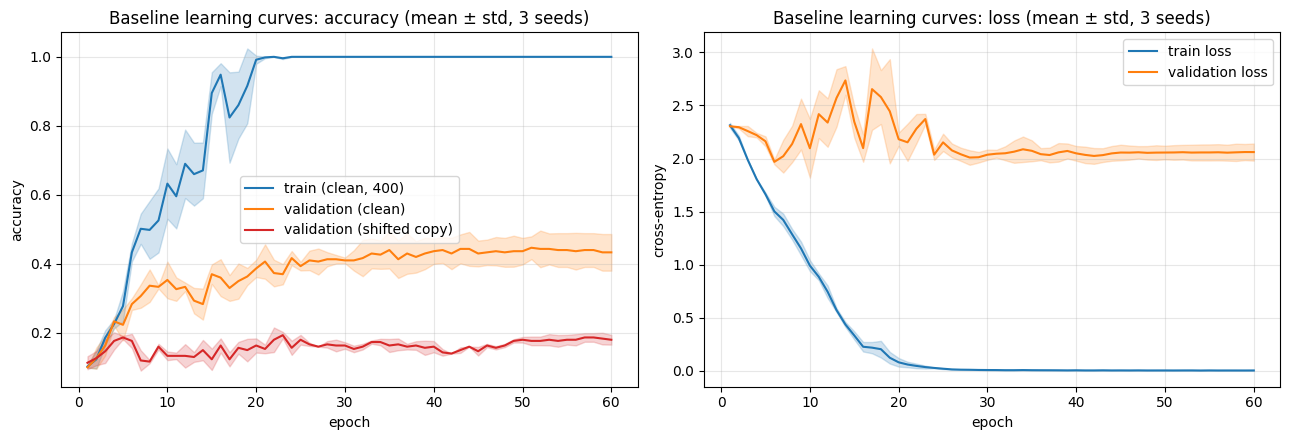

train-val gap (overfitting): 55.3 pts | clean-test -> shifted-test drop (covariate shift): 29.1 pts


In [7]:
RESULTS = {}
RESULTS['No augmentation'] = run_seeds('No augmentation', {})
R = RESULTS['No augmentation']
tab = pd.DataFrame({
    'Train acc (400 clean)': [ms([r['train_acc'] for r in R])],
    'Val acc (clean)':       [ms([r['val_acc'] for r in R])],
    'Val acc (shifted)':     [ms([r['val_shift_acc'] for r in R])],
    'Clean test':            [ms([r['clean_acc'] for r in R])],
    'Shifted test':          [ms([r['shift_acc'] for r in R])]}, index=['Baseline (mean ± std %, 3 seeds)'])
display(tab)

H = {k: np.array([r['hist'][k] for r in R]) for k in R[0]['hist']}
ep = np.arange(1, EPOCHS + 1)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for k, lab, col in [('train_acc', 'train (clean, 400)', 'C0'), ('val_acc', 'validation (clean)', 'C1'), ('val_shift_acc', 'validation (shifted copy)', 'C3')]:
    axs[0].plot(ep, H[k].mean(0), label=lab, color=col); axs[0].fill_between(ep, H[k].mean(0) - H[k].std(0), H[k].mean(0) + H[k].std(0), color=col, alpha=.2)
axs[0].set(title="Baseline learning curves: accuracy (mean ± std, 3 seeds)", xlabel="epoch", ylabel="accuracy"); axs[0].legend(); axs[0].grid(alpha=.3)
for k, lab, col in [('train_loss', 'train loss', 'C0'), ('val_loss', 'validation loss', 'C1')]:
    axs[1].plot(ep, H[k].mean(0), label=lab, color=col); axs[1].fill_between(ep, H[k].mean(0) - H[k].std(0), H[k].mean(0) + H[k].std(0), color=col, alpha=.2)
axs[1].set(title="Baseline learning curves: loss (mean ± std, 3 seeds)", xlabel="epoch", ylabel="cross-entropy"); axs[1].legend(); axs[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

tr_a, va_a = np.mean([r['train_acc'] for r in R]), np.mean([r['val_acc'] for r in R])
cl_a, sh_a = np.mean([r['clean_acc'] for r in R]), np.mean([r['shift_acc'] for r in R])
print(f"train-val gap (overfitting): {100*(tr_a-va_a):.1f} pts | clean-test -> shifted-test drop (covariate shift): {100*(cl_a-sh_a):.1f} pts")

**Diagnosis.** Training accuracy is 100%, but validation is only 44.7% and clean test 45.4%. This 55-point gap is **overfitting**: the network memorised the 400 images. On the shifted test, accuracy drops another 29 points to 16.3% (chance is 10%). This is **covariate shift**: the labels are the same but the images look different (rotated, dark, noisy, blocked), and a memorised model cannot handle that. So the failure is **both**: overfitting first, then covariate shift on top.

## Part B: Augmentation strategy

| Augmentation | Setting | Why |
|---|---|---|
| Rotation | ±25° | same range as the test rotation |
| Translation, scale | ±10%, 0.9–1.1× | objects are not centred |
| Horizontal flip | p = 0.5 | keeps the label, doubles the data |
| Brightness, contrast | ×0.5–1.5, ×0.6–1.4 | dark / bright / flat images |
| Saturation, channel shuffle | 0–1.5×, p = 0.1 | do not rely on colour only |
| Blur, noise | p = 0.3, σ ≤ 0.06 | blurry / noisy images |
| Cutout | p = 0.8, 8–18 px box | occlusion |
| Mixup / CutMix + label smoothing | 50% of batches, 0.1 | regularisation |

Augmentation is done on the fly on training batches only. Nothing is saved.

**1. Vertical flip: help or hurt?** In theory it should hurt: real photos are upright (sky on top, ground below) and the test images are never upside down, so flipped images are a distribution the model never sees later. In our run it made **no clear difference** (shifted test 19.11 vs 18.81, inside the noise). So it did not help, and there is no reason to use it.

**2. Rotation ±90° when the test is only ±25°.** *Good:* more rotation invariance. *Bad:* most training images are rotated more than the test ever is, so the small model wastes capacity. Our run shows the cost: shifted test **17.61 with ±90°** vs **18.81 with ±25°**. Match the augmentation to the expected shift.

**3. Why can too much augmentation hurt a small model?** A small model has limited capacity. If every image is changed heavily, it cannot learn the real task well (it under-fits). Very strong changes can also hide the object, so the label is no longer clear. Our results show this: clean accuracy fell from 45.4% (no augmentation) to 41.3% (final model).

In [8]:
# Small empirical check of Q1 / Q2 (3 seeds each, selection on validation only; test numbers are reporting only)
exp = {'geo (rot ±25, hflip)       [reference]': dict(geo=True),
       'geo + vertical flip': dict(geo=True, vflip=True),
       'geo with rotation ±90°': dict(geo=True, rot=90.)}
rows = []
for nm, cfg in exp.items():
    rr = run_seeds(nm, cfg)
    rows.append([nm, ms([r['val_acc'] for r in rr]), ms([r['val_shift_acc'] for r in rr]), ms([r['shift_acc'] for r in rr])])
display(pd.DataFrame(rows, columns=['Geometric variant', 'Val acc (clean) %', 'Val acc (shifted) %', 'Shifted test %']).set_index('Geometric variant'))

geo (rot ±25, hflip)       [reference]     val 0.417 | clean 0.402 | shifted 0.188  (13s)
geo + vertical flip                        val 0.443 | clean 0.375 | shifted 0.191  (13s)
geo with rotation ±90°                     val 0.380 | clean 0.336 | shifted 0.176  (13s)


,Val acc (clean) %,Val acc (shifted) %,Shifted test %
Geometric variant,,,
"geo (rot ±25, hflip) [reference]",41.67 ± 0.47,23.67 ± 1.25,18.81 ± 0.56
geo + vertical flip,44.33 ± 3.86,27.00 ± 4.55,19.11 ± 0.75
geo with rotation ±90°,38.00 ± 2.83,24.33 ± 2.05,17.61 ± 0.87


## Part C: Regularisation and training design

| Technique | Where | Why there |
|---|---|---|
| BatchNorm | after every conv | stable, faster training with the multi-branch Inception block |
| Dropout (0.3, chosen on validation) | **only after global pooling, before the final layer** | the final layer is where small data gets memorised. Early conv maps are spatially correlated, so dropout there removes little and slows learning |
| Global average pooling | replaces big FC layers | far fewer parameters, less memorising |
| Weight decay (0.005, chosen on validation) | all weights | keeps weights small, smoother model |
| OneCycle learning-rate schedule | whole training | warm-up avoids early instability, slow decay at the end settles the model |
| Early stopping | keep the epoch with best validation score | training accuracy reaches 100%, so later epochs only overfit |
| Label smoothing 0.1 | with Mixup/CutMix | avoids over-confident outputs |
| Inception module (1×1, 3×3, 5×5, pool) | twice | looks at several scales; 1×1 layers keep it small |

Search on validation only (seed 100): weight decay 0.005, dropout 0.3, mix probability 0.6 gave the best score.

In [9]:
FULL = dict(geo=True, photo=True, cutout=True, mix=True, ls=0.1)
HP_GRID = [dict(wd=w, drop=d, mix_p=m) for w in (5e-4, 5e-3) for d in (0.3, 0.5) for m in (0.3, 0.6)]
if SMOKE: HP_GRID = HP_GRID[:2]
srch = []
for hp in HP_GRID:
    r = train_eval({**FULL, **hp}, SEARCH_SEED, test=False)          # NO test data used here
    srch.append({**hp, 'val_acc': r['val_acc'], 'val_shift_acc': r['val_shift_acc'], 'val_sel': r['val_sel']})
srch = pd.DataFrame(srch).sort_values('val_sel', ascending=False).reset_index(drop=True)
display(srch)
BEST_HP = {k: float(srch.loc[0, k]) for k in ['wd', 'drop', 'mix_p']}
print("selected on validation only:", BEST_HP)

,wd,drop,mix_p,val_acc,val_shift_acc,val_sel
0,0.0050,0.3,0.6,0.47,0.32,0.395
1,0.0005,0.3,0.6,0.48,0.29,0.385
2,0.0050,0.3,0.3,0.42,0.33,0.375
3,0.0005,0.3,0.3,0.45,0.29,0.370
4,0.0005,0.5,0.6,0.40,0.32,0.360
5,0.0050,0.5,0.3,0.38,0.33,0.355
6,0.0050,0.5,0.6,0.45,0.26,0.355
7,0.0005,0.5,0.3,0.44,0.26,0.350


selected on validation only: {'wd': 0.005, 'drop': 0.3, 'mix_p': 0.6}


## Part D: Ablation (3 seeds each: 0, 1, 2)

Geometric only (crop, flip, rotation)      val 0.417 | clean 0.402 | shifted 0.188  (14s)
Photometric only (jitter, blur, noise)     val 0.487 | clean 0.407 | shifted 0.157  (14s)
Geometric + photometric                    val 0.513 | clean 0.464 | shifted 0.208  (15s)
+ Cutout / Random Erasing                  val 0.493 | clean 0.427 | shifted 0.216  (16s)
+ Mixup/CutMix + label smoothing           val 0.440 | clean 0.394 | shifted 0.212  (15s)
Final model (+ val-tuned wd/dropout/mix_p) val 0.457 | clean 0.413 | shifted 0.230  (16s)


,Val Acc,Val Acc (shifted),Clean Test,Shifted Test,Hidden-corr. only
Configuration,,,,,
No augmentation,44.67 ± 4.11,19.33 ± 0.94,45.41 ± 0.07,16.28 ± 0.90,40.16 ± 0.31
"Geometric only (crop, flip, rotation)",41.67 ± 0.47,23.67 ± 1.25,40.20 ± 3.97,18.81 ± 0.56,35.55 ± 2.77
"Photometric only (jitter, blur, noise)",48.67 ± 0.47,17.33 ± 1.25,40.68 ± 0.92,15.72 ± 0.37,38.43 ± 0.73
Geometric + photometric,51.33 ± 0.94,25.33 ± 1.25,46.37 ± 2.00,20.80 ± 1.05,41.94 ± 2.03
+ Cutout / Random Erasing,49.33 ± 5.31,28.33 ± 4.19,42.66 ± 1.54,21.64 ± 1.85,38.19 ± 2.23
+ Mixup/CutMix + label smoothing,44.00 ± 0.82,26.00 ± 0.82,39.45 ± 3.07,21.20 ± 1.47,34.24 ± 3.34
Final model (+ val-tuned wd/dropout/mix_p),45.67 ± 0.47,30.33 ± 2.49,41.26 ± 1.93,23.03 ± 0.52,36.52 ± 2.26


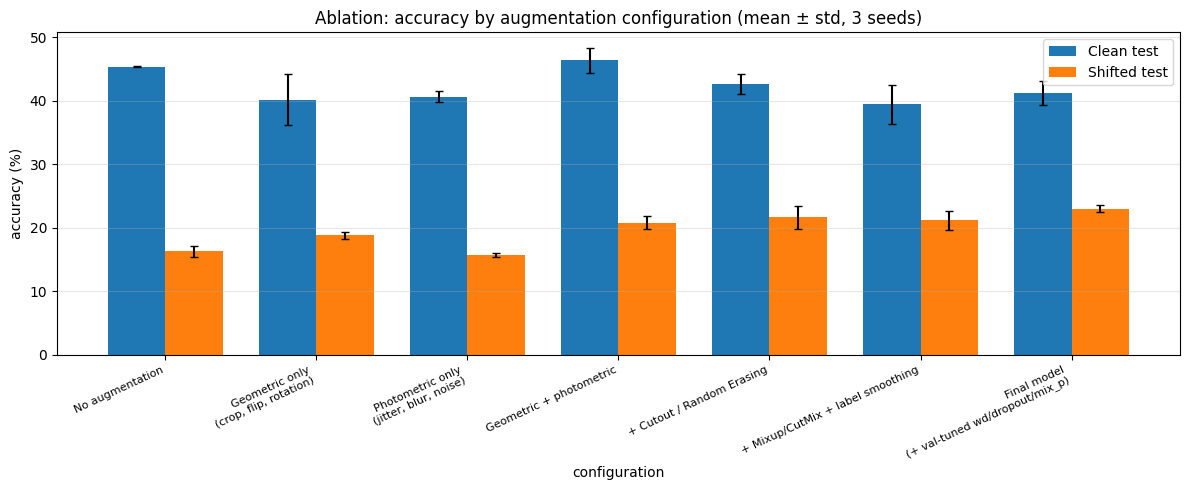

Gain over the no-augmentation baseline (shifted test, pts):
  Geometric only (crop, flip, rotation)      +2.53
  Photometric only (jitter, blur, noise)     -0.55
  Geometric + photometric                    +4.52
Incremental gain of each added component (shifted test, pts):
  Geometric + photometric vs geometric only:  +1.99
  + Cutout / Random Erasing                    vs previous row: +0.84
  + Mixup/CutMix + label smoothing             vs previous row: -0.44
  Final model (+ val-tuned wd/dropout/mix_p)   vs previous row: +1.83
largest single-family gain: Geometric + photometric


In [10]:
CONFIGS = {
 'No augmentation':                        {},
 'Geometric only (crop, flip, rotation)':  dict(geo=True),
 'Photometric only (jitter, blur, noise)': dict(photo=True),
 'Geometric + photometric':                dict(geo=True, photo=True),
 '+ Cutout / Random Erasing':              dict(geo=True, photo=True, cutout=True),
 '+ Mixup/CutMix + label smoothing':       dict(geo=True, photo=True, cutout=True, mix=True, ls=0.1),
 'Final model (+ val-tuned wd/dropout/mix_p)': {**FULL, **BEST_HP},
}
for nm, cfg in CONFIGS.items():
    if nm not in RESULTS:
        RESULTS[nm] = run_seeds(nm, cfg, keep_model=nm.startswith('Final'))

rows = []
for nm, rr in RESULTS.items():
    if nm not in CONFIGS: continue
    rows.append([nm, ms([r['val_acc'] for r in rr]), ms([r['val_shift_acc'] for r in rr]),
                 ms([r['clean_acc'] for r in rr]), ms([r['shift_acc'] for r in rr]), ms([r['hidden_acc'] for r in rr])])
ABL = pd.DataFrame(rows, columns=['Configuration', 'Val Acc', 'Val Acc (shifted)', 'Clean Test', 'Shifted Test', 'Hidden-corr. only']).set_index('Configuration')
display(ABL)

names = list(CONFIGS)
mc = lambda k: np.array([100*np.mean([r[k] for r in RESULTS[n]]) for n in names]); sc = lambda k: np.array([100*np.std([r[k] for r in RESULTS[n]]) for n in names])
fig, ax = plt.subplots(figsize=(12, 5)); w = 0.38; xx = np.arange(len(names))
ax.bar(xx - w/2, mc('clean_acc'), w, yerr=sc('clean_acc'), capsize=3, label='Clean test')
ax.bar(xx + w/2, mc('shift_acc'), w, yerr=sc('shift_acc'), capsize=3, label='Shifted test')
ax.set_xticks(xx); ax.set_xticklabels([n.replace(' (', '\n(') for n in names], rotation=25, ha='right', fontsize=8)
ax.set(title="Ablation: accuracy by augmentation configuration (mean ± std, 3 seeds)", xlabel="configuration", ylabel="accuracy (%)")
ax.legend(); ax.grid(axis='y', alpha=.3); plt.tight_layout(); plt.show()

sh = {n: 100*np.mean([r['shift_acc'] for r in RESULTS[n]]) for n in names}
print("Gain over the no-augmentation baseline (shifted test, pts):")
for n in names[1:4]: print(f"  {n:<42s} {sh[n]-sh[names[0]]:+.2f}")
print("Incremental gain of each added component (shifted test, pts):")
print(f"  Geometric + photometric vs geometric only:  {sh[names[3]]-sh[names[1]]:+.2f}")
for a, b in zip(names[3:6], names[4:7]): print(f"  {b:<44s} vs previous row: {sh[b]-sh[a]:+.2f}")
best_single = max(names[1:4], key=lambda n: sh[n]); print("largest single-family gain:", best_single)

**What helped most?**

- **Geometric** was the best single family (**+2.5 points** alone). It matches the **rotation** corruption and also adds more training variety.
- **Photometric alone did not help** (−0.6). But **geometric + photometric together gave +4.5**, so brightness/contrast/noise only helped once the model could already handle rotation.
- **Cutout** added a small **+0.8**. It matches the **occlusion** corruption, but the gain is within the seed noise (±1.9).
- **Mixup/CutMix + label smoothing** gave **−0.4**: no help. Probably too much for such a small model and data set.
- **Final model** (+1.8) comes from stronger weight decay (0.005) chosen on validation. Total gain over no augmentation: **+6.7 points** (16.3 → 23.0).

Remember: differences of about 1 point are smaller than the std, so only geometric, geometric + photometric, and the final model are clear gains. Clean accuracy went down with augmentation (45.4 → 41.3), a trade-off for robustness.

## Part E: Error analysis (final model)

,clean test acc %,shifted test acc %
class,,
airplane,52.6,25.6
automobile,66.9,21.9
bird,13.3,12.3
cat,17.6,68.5
deer,27.2,4.7
dog,20.7,2.4
frog,65.1,32.0
horse,65.7,19.9
ship,44.2,34.3


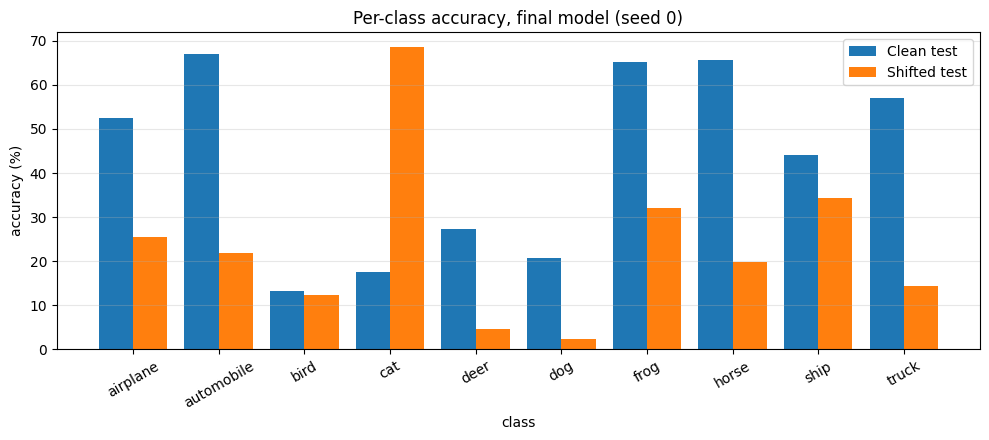

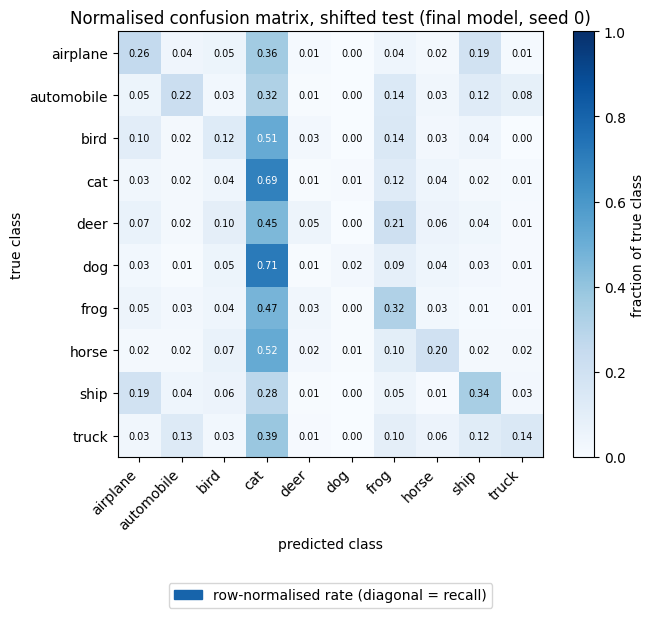

Most confused (true -> predicted, fraction of true class):
  dog        -> cat        0.71
  horse      -> cat        0.52
  bird       -> cat        0.51
  frog       -> cat        0.47
  deer       -> cat        0.45
  truck      -> cat        0.39


In [11]:
FINAL = RESULTS[names[-1]]
r0 = FINAL[0]                                                    # seed 0 for the plots below
pred_s, pred_c = r0['pred_shift'].numpy(), r0['pred_clean'].numpy(); ytrue = yte.numpy()
pc_s = np.array([(pred_s[ytrue == c] == c).mean() for c in range(10)])
pc_c = np.array([(pred_c[ytrue == c] == c).mean() for c in range(10)])
display(pd.DataFrame({'class': CLASSES, 'clean test acc %': 100*pc_c, 'shifted test acc %': 100*pc_s}).round(1).set_index('class'))

fig, ax = plt.subplots(figsize=(10, 4.5)); xx = np.arange(10)
ax.bar(xx - .2, 100*pc_c, .4, label='Clean test'); ax.bar(xx + .2, 100*pc_s, .4, label='Shifted test')
ax.set_xticks(xx); ax.set_xticklabels(CLASSES, rotation=30); ax.set(title="Per-class accuracy, final model (seed 0)", xlabel="class", ylabel="accuracy (%)")
ax.legend(); ax.grid(axis='y', alpha=.3); plt.tight_layout(); plt.show()

cm = confusion_matrix(ytrue, pred_s, normalize='true')
fig, ax = plt.subplots(figsize=(7.5, 6.5)); im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.set_xticklabels(CLASSES, rotation=45, ha='right'); ax.set_yticklabels(CLASSES)
for i in range(10):
    for j in range(10): ax.text(j, i, f"{cm[i,j]:.2f}", ha='center', va='center', fontsize=7, color='white' if cm[i, j] > .5 else 'black')
ax.set(title="Normalised confusion matrix, shifted test (final model, seed 0)", xlabel="predicted class", ylabel="true class")
plt.colorbar(im, ax=ax, fraction=.046, label="fraction of true class")
ax.legend(handles=[Patch(color=plt.cm.Blues(.8), label='row-normalised rate (diagonal = recall)')], loc='upper center', bbox_to_anchor=(.5, -.28))
plt.tight_layout(); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
top = sorted([(off[i, j], i, j) for i in range(10) for j in range(10)], reverse=True)[:6]
print("Most confused (true -> predicted, fraction of true class):")
for v, i, j in top: print(f"  {CLASSES[i]:<10s} -> {CLASSES[j]:<10s} {v:.2f}")

**Most confused classes.** The model sends many classes to **cat** on shifted images: dog→cat 71%, horse→cat 52%, bird→cat 51%, frog→cat 47%, deer→cat 45%, truck→cat 39%. That is why cat shows 68.5% shifted accuracy but only 17.6% on clean images. It looks like a **default guess**: when the image is dark, blurred or blocked, the model has little evidence and answers "cat". Dog→cat is also a natural confusion (similar fur, pose and size at 32×32). Dog (2.4%) and deer (4.7%) are almost never correct on shifted images. The model is weak overall (41% on clean test), so this is mostly a limit of the tiny training set.

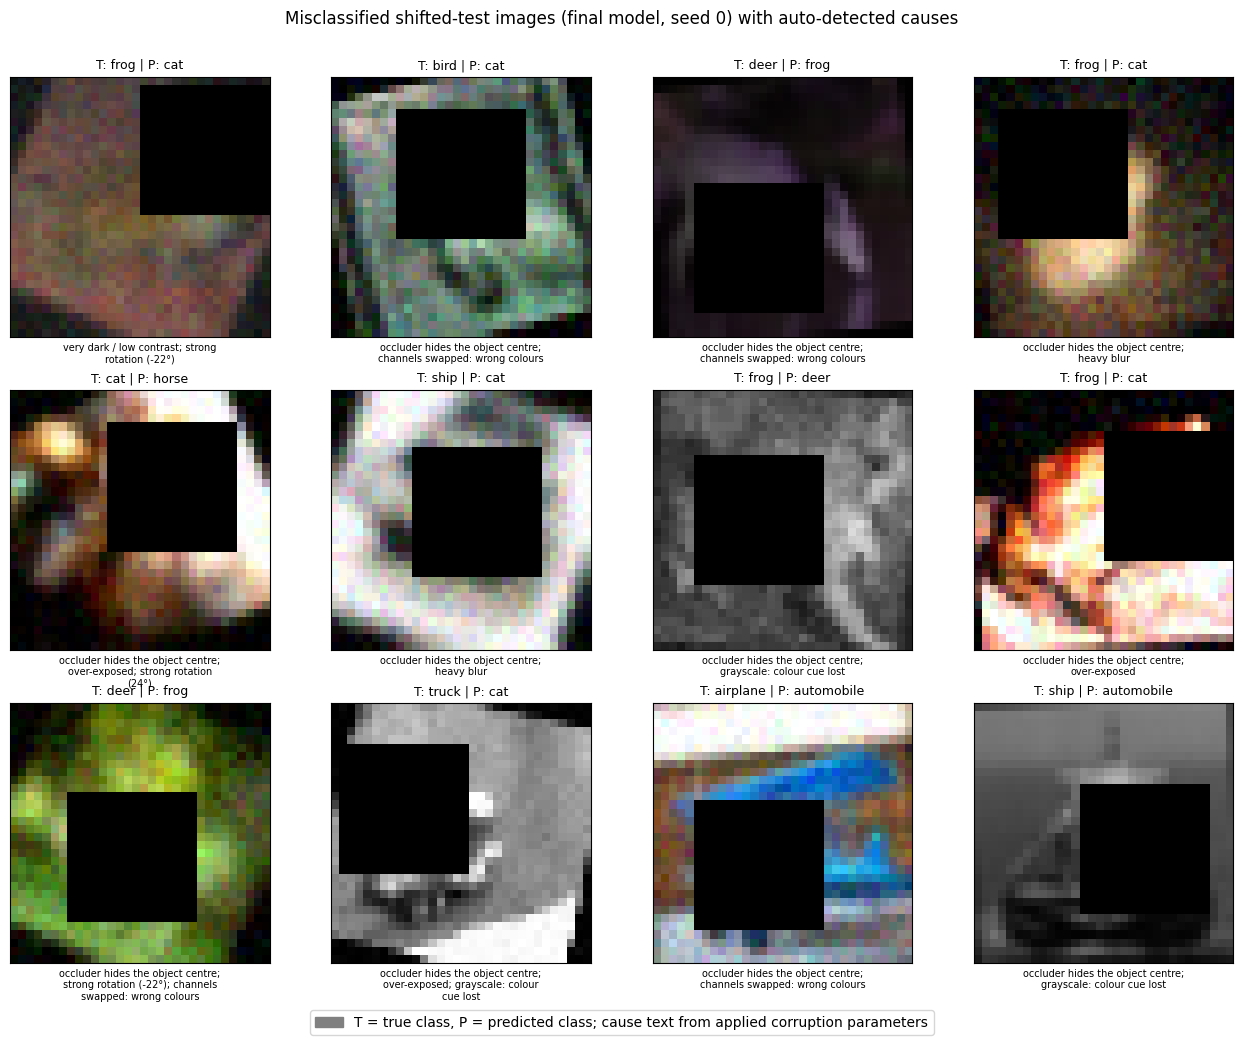

img  5865  true=frog       pred=cat        -> very dark / low contrast; strong rotation (-22°)
img  6387  true=bird       pred=cat        -> occluder hides the object centre; channels swapped: wrong colours
img  2981  true=deer       pred=frog       -> occluder hides the object centre; channels swapped: wrong colours
img  5715  true=frog       pred=cat        -> occluder hides the object centre; heavy blur
img  7323  true=cat        pred=horse      -> occluder hides the object centre; over-exposed; strong rotation (24°)
img  1216  true=ship       pred=cat        -> occluder hides the object centre; heavy blur
img  8846  true=frog       pred=deer       -> occluder hides the object centre; grayscale: colour cue lost
img  1327  true=frog       pred=cat        -> occluder hides the object centre; over-exposed
img  6866  true=deer       pred=frog       -> occluder hides the object centre; strong rotation (-22°); channels swapped: wrong colours
img   744  true=truck      pred=cat        -> o

In [12]:
# ---- 12 misclassified shifted-test images with the corruption parameters that were applied --------------
wrong = np.where(pred_s != ytrue)[0]
sel = np.random.RandomState(0).choice(wrong, 12, replace=False)
def reasons(i):
    m = {k: v[i].item() for k, v in META_SH.items()}; out = []
    ov = max(0, min(m['top'] + 16, 24) - max(m['top'], 8)) * max(0, min(m['left'] + 16, 24) - max(m['left'], 8))
    if ov >= 90: out.append("occluder hides the object centre")
    if m['bright'] * m['contrast'] < 0.55: out.append("very dark / low contrast")
    if m['bright'] > 1.35: out.append("over-exposed")
    if abs(m['angle']) > 18: out.append(f"strong rotation ({m['angle']:.0f}°)")
    if m['sigma'] > 0.9: out.append("heavy blur")
    if m['hidden'] == 1: out.append("grayscale: colour cue lost")
    if m['hidden'] == 2: out.append("channels swapped: wrong colours")
    return "; ".join(out) if out else "no strong corruption: inter-class similarity"
fig, axs = plt.subplots(3, 4, figsize=(13, 10.5))
for ax, i in zip(axs.ravel(), sel):
    ax.imshow(Xte_shift[i].permute(1, 2, 0).clamp(0, 1).numpy()); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"T: {CLASSES[ytrue[i]]} | P: {CLASSES[pred_s[i]]}", fontsize=9)
    ax.set_xlabel(textwrap.fill(reasons(i), 34), fontsize=7)
fig.suptitle("Misclassified shifted-test images (final model, seed 0) with auto-detected causes")
fig.legend(handles=[Patch(color='gray', label='T = true class, P = predicted class; cause text from applied corruption parameters')], loc='lower center')
plt.tight_layout(rect=(0, 0.03, 1, 0.97)); plt.show()
for i in sel: print(f"img {i:5d}  true={CLASSES[ytrue[i]]:<10s} pred={CLASSES[pred_s[i]]:<10s} -> {reasons(i)}")

**Misclassified images (12 shown).** The cause listed under each image comes from the exact corruption applied to it. In 11 of 12, the **black box covers the centre of the object**. Several also have a second problem: channels swapped or grayscale (7), heavy blur (2), over-exposure (3) or strong rotation (3). Six of the 12 were predicted as **cat**, which matches the "default guess" behaviour above. Only the dark, rotated frog (img 5865) has no occluder on the object, and there darkness and rotation are the problem.

clean test (no corruption)       baseline 45.41 ± 0.07 | final 41.26 ± 1.93
clean test + hidden corr. only   baseline 40.16 ± 0.31 | final 36.52 ± 2.26


,n images,final model acc % (seed 0)
subset,,
untouched,5027,43.6
grayscale,2486,35.7
channel swap,2487,30.8


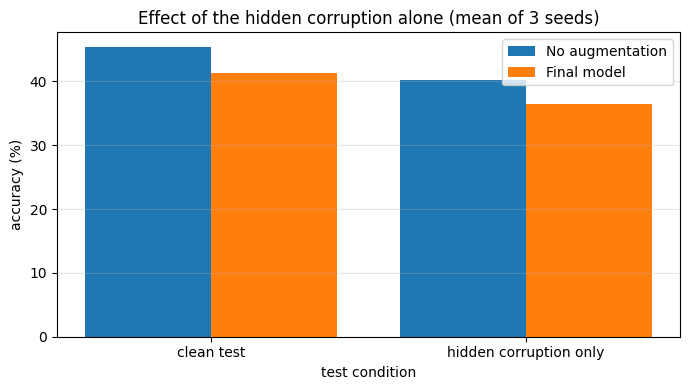

In [13]:
# ---- E4: hidden corruption applied alone to the clean test set ------------------------------------------
base, fin = RESULTS['No augmentation'], FINAL
print(f"clean test (no corruption)       baseline {ms([r['clean_acc'] for r in base])} | final {ms([r['clean_acc'] for r in fin])}")
print(f"clean test + hidden corr. only   baseline {ms([r['hidden_acc'] for r in base])} | final {ms([r['hidden_acc'] for r in fin])}")
ph = r0['pred_hidden'].numpy(); kind = KIND_HID.numpy()
sub = pd.DataFrame({'subset': ['untouched', 'grayscale', 'channel swap'],
                    'n images': [(kind == k).sum() for k in range(3)],
                    'final model acc % (seed 0)': [100 * (ph[kind == k] == ytrue[kind == k]).mean() for k in range(3)]}).round(1)
display(sub.set_index('subset'))
fig, ax = plt.subplots(figsize=(7, 4)); lab = ['clean test', 'hidden corruption only']
ax.bar(np.arange(2) - .2, [100*np.mean([r['clean_acc'] for r in base]), 100*np.mean([r['hidden_acc'] for r in base])], .4, label='No augmentation')
ax.bar(np.arange(2) + .2, [100*np.mean([r['clean_acc'] for r in fin]),  100*np.mean([r['hidden_acc'] for r in fin])],  .4, label='Final model')
ax.set_xticks(range(2)); ax.set_xticklabels(lab); ax.set(title="Effect of the hidden corruption alone (mean of 3 seeds)", xlabel="test condition", ylabel="accuracy (%)")
ax.legend(); ax.grid(axis='y', alpha=.3); plt.tight_layout(); plt.show()

**Hidden corruption alone** (our implementation: random grayscale or channel swap, on clean test images):

| | Clean test | Hidden corruption only | Drop |
|---|---|---|---|
| No augmentation | 45.41 | 40.16 | −5.3 |
| Final model | 41.26 | 36.52 | −4.7 |

Our augmentation **did not generalise much** to this corruption: the final model lost about as much as the baseline (−4.7 vs −5.3), and its absolute accuracy is lower. For the final model (seed 0), accuracy was 43.6% on untouched images, 35.7% on grayscale and 30.8% on channel-swapped images, so **channel swaps hurt more**. Our colour augmentation only shuffled channels in 10% of images, which was not enough. Note: our training augmentation already contains similar colour operations (saturation down to 0, channel shuffles), so this is not a fully blind test, and the real effect on a different unseen corruption could be larger.

## Part F (bonus): Test-time augmentation

,Shifted-test acc %,Δ vs N=1 (pts),Inference time / 10k imgs (s),Cost vs N=1
N views,,,,
1,23.03 ± 0.52,+0.00,0.23,1.0×
2,23.35 ± 0.62,+0.31,0.46,2.0×
4,22.93 ± 0.70,-0.10,0.93,4.1×
8,22.48 ± 0.53,-0.55,1.86,8.3×


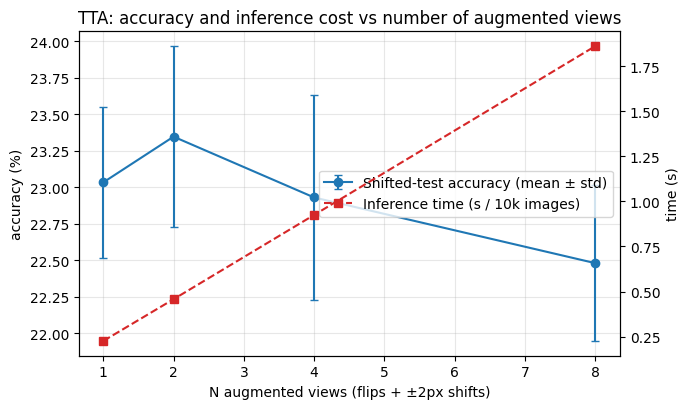

In [14]:
def shift_img(x, dx, dy):
    p = F.pad(x, (2, 2, 2, 2)); return p[:, :, 2 - dy:34 - dy, 2 - dx:34 - dx]
flip = lambda x: x.flip(3)
VIEWS = [lambda x: x, flip, lambda x: shift_img(x, 2, 0), lambda x: shift_img(x, -2, 0),
         lambda x: shift_img(x, 0, 2), lambda x: shift_img(x, 0, -2),
         lambda x: flip(shift_img(x, 2, 2)), lambda x: flip(shift_img(x, -2, -2))]

@torch.no_grad()
def tta_acc(state, X, Y, n):
    m = Net(FINAL[0]['cfg']['drop']).to(device); m.load_state_dict(state); m.eval()
    if device.type == 'cuda': torch.cuda.synchronize()
    t0 = time.time(); probs = 0
    for v in VIEWS[:n]:
        probs = probs + torch.cat([F.softmax(m(v(X[i:i+1000].to(device))), 1) for i in range(0, len(X), 1000)])
    if device.type == 'cuda': torch.cuda.synchronize()
    return (probs.argmax(1).cpu() == Y).float().mean().item(), time.time() - t0

_ = tta_acc(FINAL[0]['state'], Xte_shift[:1000], yte[:1000], 1)      # warm-up (excluded from timing)
rows = []
for n in [1, 2, 4, 8]:
    out = [tta_acc(r['state'], Xte_shift, yte, n) for r in FINAL]
    rows.append(dict(N_views=n, acc=[o[0] for o in out], t=np.mean([o[1] for o in out])))
tt = pd.DataFrame({'N views': [r['N_views'] for r in rows], 'Shifted-test acc %': [ms(r['acc']) for r in rows],
                   'Δ vs N=1 (pts)': [f"{100*(np.mean(r['acc'])-np.mean(rows[0]['acc'])):+.2f}" for r in rows],
                   'Inference time / 10k imgs (s)': [f"{r['t']:.2f}" for r in rows],
                   'Cost vs N=1': [f"{r['t']/rows[0]['t']:.1f}×" for r in rows]}).set_index('N views')
display(tt)
fig, ax = plt.subplots(figsize=(7, 4.2)); a = [100*np.mean(r['acc']) for r in rows]; e = [100*np.std(r['acc']) for r in rows]
l1 = ax.errorbar([r['N_views'] for r in rows], a, yerr=e, marker='o', capsize=3, label='Shifted-test accuracy (mean ± std)')
ax.set(title="TTA: accuracy and inference cost vs number of augmented views", xlabel="N augmented views (flips + ±2px shifts)", ylabel="accuracy (%)"); ax.grid(alpha=.3)
ax2 = ax.twinx(); l2, = ax2.plot([r['N_views'] for r in rows], [r['t'] for r in rows], 's--', color='C3', label='Inference time (s / 10k images)'); ax2.set_ylabel("time (s)")
ax.legend(handles=[l1, l2], loc='center right'); plt.tight_layout(); plt.show()

**TTA result.** Averaging predictions over flipped and shifted copies did **not help**: 23.03 (N=1), 23.35 (N=2), 22.93 (N=4), 22.48 (N=8). The change is within the noise, and it gets slightly worse at N=8. The cost is linear: N=8 takes **8.3×** longer (0.23 s → 1.86 s per 10,000 images). Here the extra cost is not worth it.

## Reproducibility summary

In [15]:
print("seeds  :", dict(data=DATA_SEED, train=EVAL_SEEDS, search=SEARCH_SEED, shifted_test=SHIFT_TEST_SEED, shifted_val=SHIFT_VAL_SEED))
print("split  : 400 train / 100 val (40 / 10 per class) from 500 train_small; md5 =", hashlib.md5(np.concatenate([tr_idx, va_idx]).tobytes()).hexdigest()[:12])
print("model  : %s trainable parameters (limit 1,000,000), epochs = %d, batch = %d" % (f"{n_params:,}", EPOCHS, BATCH))
print("selected hyper-parameters (validation only):", BEST_HP)
print("test sets used for reporting only; hidden corruption =", hidden_corruption.__doc__.strip().split('\n')[0])

seeds  : {'data': 0, 'train': [0, 1, 2], 'search': 100, 'shifted_test': 2024, 'shifted_val': 777}
split  : 400 train / 100 val (40 / 10 per class) from 500 train_small; md5 = ff2aa4f680a8
model  : 332,714 trainable parameters (limit 1,000,000), epochs = 60, batch = 64
selected hyper-parameters (validation only): {'wd': 0.005, 'drop': 0.3, 'mix_p': 0.6}
test sets used for reporting only; hidden corruption = Hidden corruption (exact details were not provided, so this is our own implementation).
